<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS08/tugas1_js08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Import library dan membaca dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv("/content/CC_Customer_Dataset.csv")

print("Ukuran dataset:", df.shape)
print("Nama kolom:", df.columns.tolist())

df.head()

Ukuran dataset: (660, 7)
Nama kolom: ['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


**2. Persiapan data**

In [2]:
# Rapikan nama kolom
df.columns = df.columns.str.strip()

# Identifikasi kolom ID dan keluarkan dari fitur
id_cols = [
    col for col in df.columns
    if col.lower().replace(" ", "").replace("_", "")
    in ["customerkey", "customerid", "id"]
]

# Ambil seluruh fitur numerik yang relevan
X_df = df.drop(columns=id_cols).select_dtypes(include=np.number)

# Tangani missing value
X_df = X_df.replace([np.inf, -np.inf], np.nan)
valid_rows = X_df.notna().all(axis=1)

X_df = X_df.loc[valid_rows].copy()
df_clean = df.loc[valid_rows].copy()

# Standardisasi fitur
scaler = StandardScaler()
X = scaler.fit_transform(X_df)

print("Jumlah data yang digunakan:", X.shape[0])
print("Fitur yang digunakan:", X_df.columns.tolist())

Jumlah data yang digunakan: 660
Fitur yang digunakan: ['Sl_No', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


**3. Menentukan jumlah cluster terbaik**

In [3]:
hasil_evaluasi = []

for k in range(2, 11):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X)

    hasil_evaluasi.append({
        "Jumlah Cluster": k,
        "Silhouette Score": silhouette_score(X, labels),
        "DBI": davies_bouldin_score(X, labels)
    })

evaluasi = pd.DataFrame(hasil_evaluasi)

print(evaluasi.round(4).to_string(index=False))

k_terbaik = int(
    evaluasi.loc[
        evaluasi["Silhouette Score"].idxmax(),
        "Jumlah Cluster"
    ]
)

print("\nJumlah cluster terbaik berdasarkan Silhouette Score:", k_terbaik)

 Jumlah Cluster  Silhouette Score    DBI
              2            0.4453 0.8633
              3            0.5305 0.6695
              4            0.3766 1.0768
              5            0.2679 1.3926
              6            0.2389 1.3488
              7            0.2346 1.4877
              8            0.2115 1.6249
              9            0.2152 1.4477
             10            0.2033 1.4914

Jumlah cluster terbaik berdasarkan Silhouette Score: 3


**4. Membuat model Agglomerative Clustering**

In [4]:
agg = AgglomerativeClustering(
    n_clusters=k_terbaik,
    linkage="ward"
)

labels = agg.fit_predict(X)

df_clean["Cluster"] = labels

print("Jumlah anggota setiap cluster:")
print(df_clean["Cluster"].value_counts().sort_index())

Jumlah anggota setiap cluster:
Cluster
0    384
1    226
2     50
Name: count, dtype: int64


**5. Scatterplot berdasarkan dua variabel**

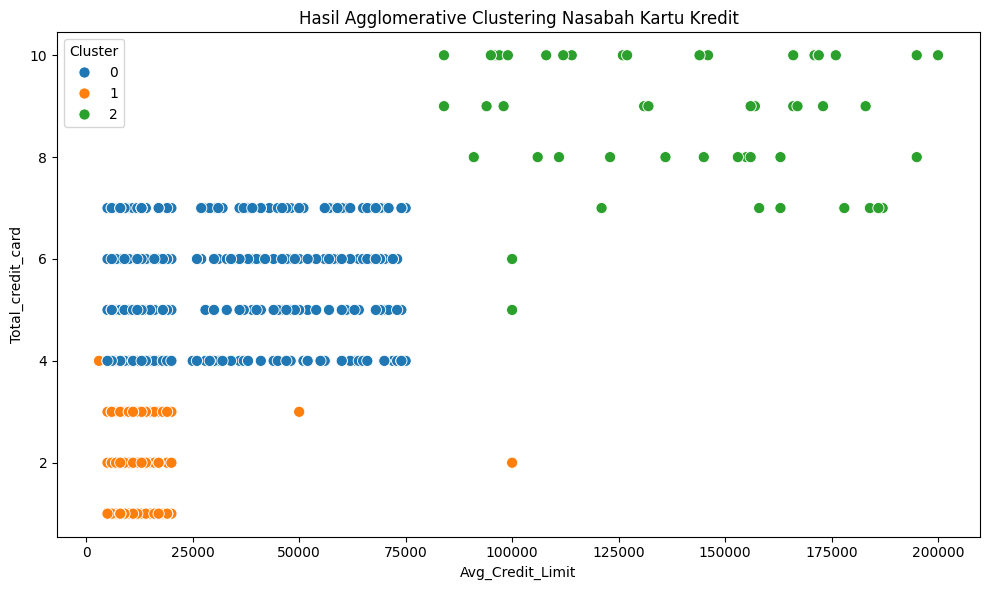

In [5]:
def normalisasi_nama(nama):
    return "".join(c.lower() for c in nama if c.isalnum())

kolom_map = {
    normalisasi_nama(col): col for col in df_clean.columns
}

kolom_x = kolom_map.get("avgcreditlimit")

kolom_y = (
    kolom_map.get("totalcreditcard")
    or kolom_map.get("totalcreditcards")
)

if kolom_x is None or kolom_y is None:
    raise ValueError(
        "Kolom Avg_Credit_Limit atau Total_credit_card "
        "tidak ditemukan. Periksa nama kolom dengan df.columns."
    )

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x=kolom_x,
    y=kolom_y,
    hue="Cluster",
    palette="tab10",
    s=65
)

plt.title("Hasil Agglomerative Clustering Nasabah Kartu Kredit")
plt.xlabel("Avg_Credit_Limit")
plt.ylabel("Total_credit_card")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

**6. Menghitung Silhouette Score dan DBI**

In [6]:
silhouette = silhouette_score(X, labels)
dbi = davies_bouldin_score(X, labels)

print(f"Jumlah cluster       : {k_terbaik}")
print(f"Silhouette Score     : {silhouette:.4f}")
print(f"Davies-Bouldin Index : {dbi:.4f}")

Jumlah cluster       : 3
Silhouette Score     : 0.5305
Davies-Bouldin Index : 0.6695


**Kesimpulan**


Berdasarkan hasil klasterisasi menggunakan algoritma Agglomerative Clustering dengan metode linkage Ward, data nasabah kartu kredit dikelompokkan menjadi **[jumlah cluster terbaik] cluster**. Pembentukan cluster dilakukan menggunakan seluruh fitur numerik yang relevan setelah proses standardisasi, dengan mengecualikan kolom identitas nasabah.

Visualisasi scatterplot menggunakan variabel Avg_Credit_Limit dan Total_credit_card menunjukkan persebaran nasabah berdasarkan hasil pengelompokan model. Kedua variabel tersebut digunakan untuk visualisasi, sedangkan pembentukan cluster menggunakan seluruh fitur yang telah dipilih.

Evaluasi model menghasilkan Silhouette Score sebesar **[nilai silhouette]** dan Davies-Bouldin Index sebesar **[nilai DBI]**. Silhouette Score digunakan untuk menilai pemisahan antarkluster, sedangkan DBI digunakan untuk menilai kekompakan dan keterpisahan cluster. Kedua metrik tersebut menjadi dasar untuk mengevaluasi kualitas hasil klasterisasi.
